# 评估和预测客户的重复购买行为

如果你还没看过“客户价值分析ii"，建议先阅读它。

本篇内容主要为代码&建模。

# 回顾

![demo](./resource/image/whiteboard.png)




- frequency = 买了多少次（重复购买次数）
- recency   = 从第一次买到最后一次买，跨度多久
- T         = 从第一次买到观察期结束，跨度多久/ 也可以理解为“age“

**BG/NBD Assumptions**

1. while active , the time between transactions is distributed exponentially with transaction rate , ie.
$$
 f(t_j| t_j-1 ;\lambda) = \lambda exp(-\lambda(t_j - t_{j-1} ), \quad t_j \ge t_{j-1} \ge0
$$

2. heterogeneity in $\lambda$ follows a gamma distribution with pdf(Probability Density Function)
$$
f(\lambda | r,\alpha) = \frac{ \alpha^r \lambda ^{r^1} exp(-\lambda \alpha)}{ \Gamma(r)}, \quad \lambda > 0
$$


3. After any transaction, a customer becomes inactive with probability p
4. Heterogeneity in $p$ follows a beta distribution with pdf

$$
f(p|a,b) = \frac{\Gamma(a+b)}{\Gamma(a)\Gamma(b)} p^{a-1}(1-p)^{b-1}, \quad 0 \le p \le 1
$$

5. the transaction rate $\lambda $ and the dropout probability p vary independently across customers


In [80]:
%matplotlib inline

import numpy as np
import pandas as pd

from pymc_marketing import clv
from pymc_marketing.clv import plotting
import arviz as az
import arviz_plots as azp

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.graph_objects as go

# from matplotlib import font_manager
# from scipy.stats import nbinom, poisson



OUT = "./cleaned_online_retail_II.csv"

> 本notebook使用另一个库 pymc ,理论与基础功能上，与lifetimes库是完全一样的。



# clv 

### read data

In [20]:

OUT = "./cleaned_online_retail_II.csv"
df = pd.read_csv(
    OUT,
    parse_dates=["InvoiceDate"]
)


### BG/NBD 

![alt text](./resource/image/image.png)

In [21]:
train_end = pd.Timestamp("2011-06-01")
data_str = df["InvoiceDate"].min()
data_end = df["InvoiceDate"].max()

rfm = clv.rfm_train_test_split(df,
                    train_period_end=train_end,
                    test_period_end=data_end,
                    customer_id_col="Customer ID",  
                    datetime_col="InvoiceDate",  
                    monetary_value_col="TotalPrice", 
                    datetime_format="%Y-%m-%d %H:%M:%S",  
                    time_unit="D",  
                          )

In [6]:
rfm.head()

,customer_id,frequency,recency,T,monetary_value,test_frequency,test_monetary_value,test_T
0,12346,7.0,400.0,534.0,11066.637143,0.0,0.0000,191.0
1,12347,3.0,158.0,213.0,607.810000,4.0,621.6425,191.0
2,12348,3.0,190.0,247.0,389.080000,1.0,270.0000,191.0
3,12349,1.0,182.0,398.0,1152.620000,1.0,1457.5500,191.0
4,12350,0.0,0.0,119.0,0.000000,0.0,0.0000,191.0


In [7]:
rfm[["monetary_value", "frequency"]].corr()

,monetary_value,frequency
monetary_value,1.000000,0.229286
frequency,0.229286,1.000000


In [23]:
bgm = clv.BetaGeoModel(data=rfm)  
bgm.fit()  
bgm.fit_summary()  

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, phi_dropout, kappa_dropout, r]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 15 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,60.933,2.029,57.383,64.841,0.045,0.038,2075.0,2321.0,1.0
phi_dropout,0.049,0.006,0.038,0.061,0.000,0.000,2426.0,2698.0,1.0
kappa_dropout,3.218,0.868,1.787,4.843,0.018,0.017,2288.0,2358.0,1.0
r,0.646,0.017,0.614,0.678,0.000,0.000,2059.0,1973.0,1.0
a,0.152,0.029,0.099,0.206,0.001,0.000,3158.0,2787.0,1.0
b,3.066,0.843,1.732,4.689,0.018,0.016,2275.0,2388.0,1.0


In [24]:
# 样本外验证：预测测试窗口的购买次数，对比 test_frequency  
pred = bgm.expected_purchases(rfm, future_t=rfm["test_T"])  
  

### Gamma-Gamma

Fader, P. S., & Hardie, B. G. (2013).
[The Gamma-Gamma model of monetary value](http://www.brucehardie.com/notes/025/gamma_gamma.pdf)


In [25]:
# 拟合 Gamma-Gamma —— 必须先过滤 frequency>0 的客户  
gg_data = rfm.query("frequency > 0")  
gg = clv.GammaGammaModel(data=gg_data)  
gg.fit()  

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [p, q, v]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 10 seconds.


Inference data with groups:
	> posterior
	> sample_stats
	> fit_data

In [26]:
#  合并计算 CLV  
clv_estimate = gg.expected_customer_lifetime_value(  
    transaction_model=bgm,  
    data=rfm,  
    future_t=12,  # month
    discount_rate=0.01,  
    time_unit="D",  
)

## plot && analysis

###  expected purchases

1. 绘制purchase的历史累积图，分析比较模型拟合的总体趋势
2. 绘制purchase的日增图，评估潜在风险/灵敏度


<Axes: title={'center': 'Tracking Cumulative Transactions'}, xlabel='Time Periods', ylabel='Purchases'>

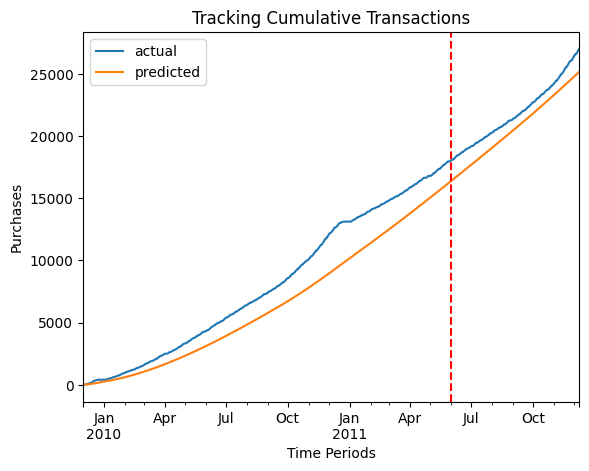

In [12]:
# 看模型对历史购买趋势的还原
clv.plot_expected_purchases_over_time(
    model=bgm,
    purchase_history=df,    # 全量原始流水
    datetime_col="InvoiceDate",
    customer_id_col="Customer ID",         
    datetime_format="%Y-%m-%d %H:%M:%S",  
    time_unit="D",
    t=(data_end-data_str).days,                          # 总天数 = 训练期 + 测试期
    t_start_eval=(train_end-data_str).days,               # 测试期起点（训练期的长度）
    set_index_date=True,           # 让x轴显示日期而不是天数
)

总体预测与实际数据高度契合，没有出现严重的偏离或发散，

但是实际下单量出现了一段上升/（斜率变大），在横轴 Oct 2010 - Jan 2011附近。


> 模型的估计一般偏保守。如果模型预测值低于实际值很多，又依赖该模型进行预算制定、库存准备、供应链规划或资源配置，可能会导致错失市场需求或造成服务质量下降。

> 累计曲线天然具有“只增不减”的特性，会给人一种虚假繁荣的幻影。





<Axes: title={'center': 'Tracking Incremental Transactions'}, xlabel='Time Periods', ylabel='Purchases'>

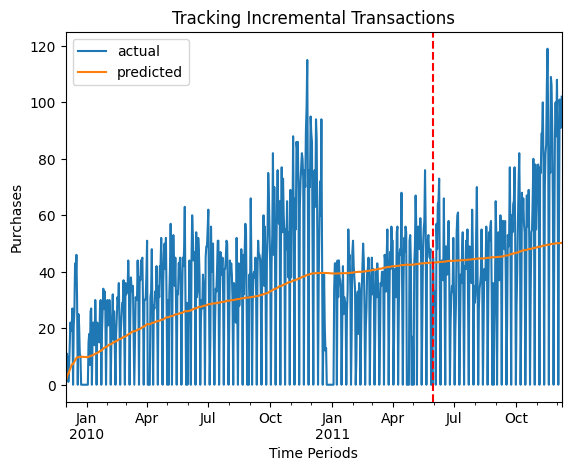

In [13]:
# 增量日购买行为
clv.plot_expected_purchases_over_time(
    model=bgm,
    purchase_history=df,    # 清洗过的transaction数据
    datetime_col="InvoiceDate",
    customer_id_col="Customer ID",         
    datetime_format="%Y-%m-%d %H:%M:%S",  
    time_unit="D",
    t=(data_end-data_str).days,                          # 总天数 = 训练期 + 测试期
    t_start_eval=(train_end-data_str).days,               # 测试期起点（训练期的长度）
    set_index_date=True,           # 让x轴显示日期而不是天数
    plot_cumulative=False
)


增量图十分重要，能展示出更多累计图掩盖的细节：

- 强烈的季节性/周期性
- 蓝线频繁触及底部 0，频繁波动

### expected customer spend

1. 每次交易的客户预期的spend
2. 未来时间客户预期的的spend，即客户终生价值

#### monetary value

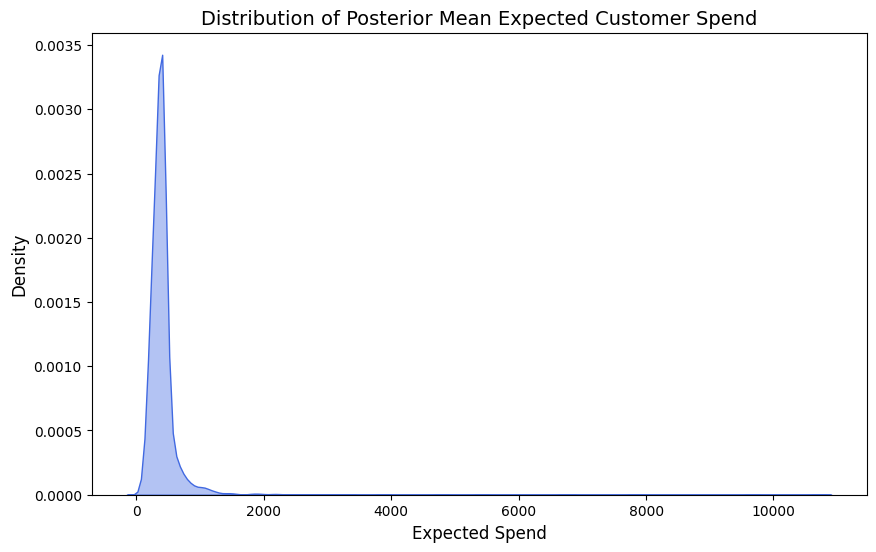

In [14]:
expected_spend = gg.expected_customer_spend(data=rfm)


# 1. 跨 chain 和 draw 求每个客户的点估计
mean_spend_per_customer = expected_spend.mean(dim=["chain", "draw"])

# 2. seaborn 绘制核密度估计图
plt.figure(figsize=(10, 6))
sns.kdeplot(mean_spend_per_customer.values, fill=True, color="royalblue", alpha=0.4)
plt.title("Distribution of Posterior Mean Expected Customer Spend", fontsize=14)
plt.xlabel("Expected Spend", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.show()

偏右重尾分布

In [15]:
az.summary(expected_spend.isel(customer_id=range(10)), kind="stats")


,mean,sd,hdi_3%,hdi_97%
x[12346],9672.301,109.150,9485.539,9890.114
x[12347],554.733,4.299,547.254,563.386
x[12348],392.787,1.605,389.804,395.754
x[12349],768.913,17.992,735.548,803.244
x[12350],403.480,6.379,391.459,415.333
x[12351],403.480,6.379,391.459,415.333
x[12352],209.188,2.922,204.043,214.876
x[12353],250.018,6.881,236.471,262.078
x[12354],403.480,6.379,391.459,415.333
x[12355],430.720,3.815,423.072,437.427


Text(0.5, 1.0, 'Expected Spend')

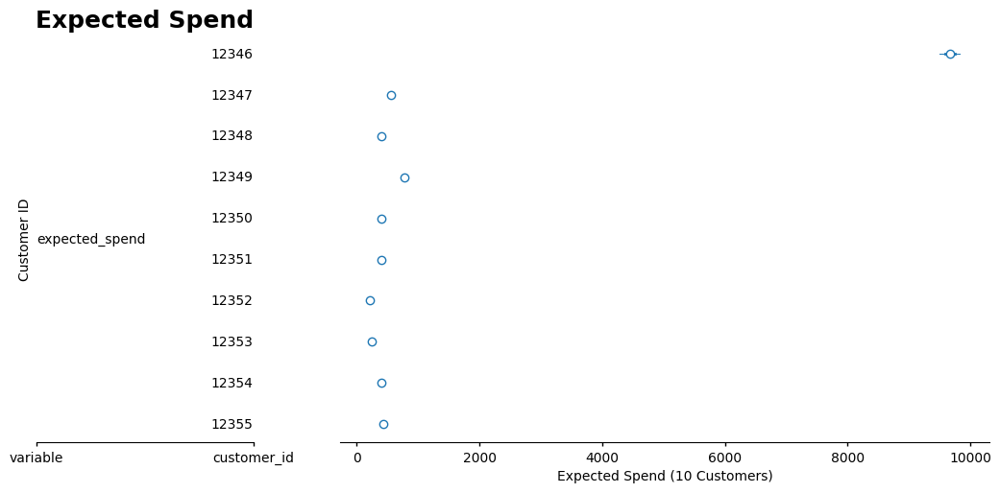

In [16]:
# 选10个样本客户查看平均花费
pc = azp.plot_forest(
    expected_spend.isel(customer_id=range(10)).to_dataset(name="expected_spend"),
    combined=True,
    plot_kwargs={"figsize": (8, 7)},
)
fig = pc.viz["chart"].item()
axes = pc.viz["plot"].values
label_ax, forest_ax = axes      # ['labels', 'forest']
forest_ax.set(xlabel="Expected Spend (10 Customers)")
label_ax.set(ylabel="Customer ID")
label_ax.set_title("Expected Spend", fontsize=18, fontweight="bold")



In [17]:
# 平均spend
az.summary(expected_spend.mean("customer_id"), kind="stats")

,mean,sd,hdi_3%,hdi_97%
x,410.448,3.248,404.413,416.513


平均每单的用户花费是410

#### clv

In [19]:
mean_clv_per_customer = clv_estimate.mean(dim=["chain", "draw"])

In [20]:
az.summary(clv_estimate.mean("customer_id"), kind="stats")

,mean,sd,hdi_3%,hdi_97%
x,1349.261,12.451,1326.689,1372.809


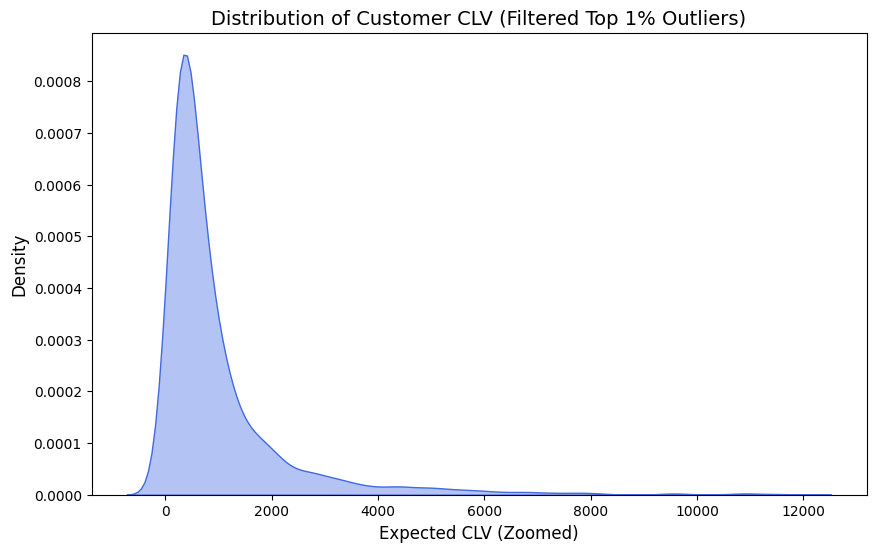

In [21]:

values = mean_clv_per_customer.values

# 计算 99分位，过滤离群值
upper_limit = np.percentile(values, 99)
filtered_values = values[values <= upper_limit]

plt.figure(figsize=(10, 6))
sns.kdeplot(filtered_values, fill=True, color="royalblue", alpha=0.4)
plt.title("Distribution of Customer CLV (Filtered Top 1% Outliers)", fontsize=14)
plt.xlabel("Expected CLV (Zoomed)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.show()

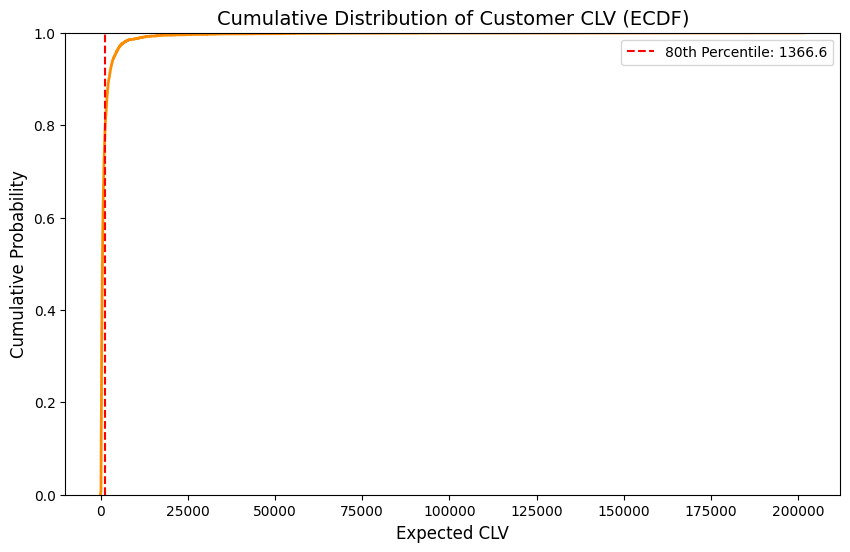

In [22]:
plt.figure(figsize=(10, 6))
sns.ecdfplot(values, color="darkorange", linewidth=2)

# 可选：加上 80% 或 90% 的分位数参考线
p80 = np.percentile(values, 80)
plt.axvline(p80, color="red", linestyle="--", label=f"80th Percentile: {p80:.1f}")

plt.title("Cumulative Distribution of Customer CLV (ECDF)", fontsize=14)
plt.xlabel("Expected CLV", fontsize=12)
plt.ylabel("Cumulative Probability", fontsize=12)
plt.legend()
plt.show()

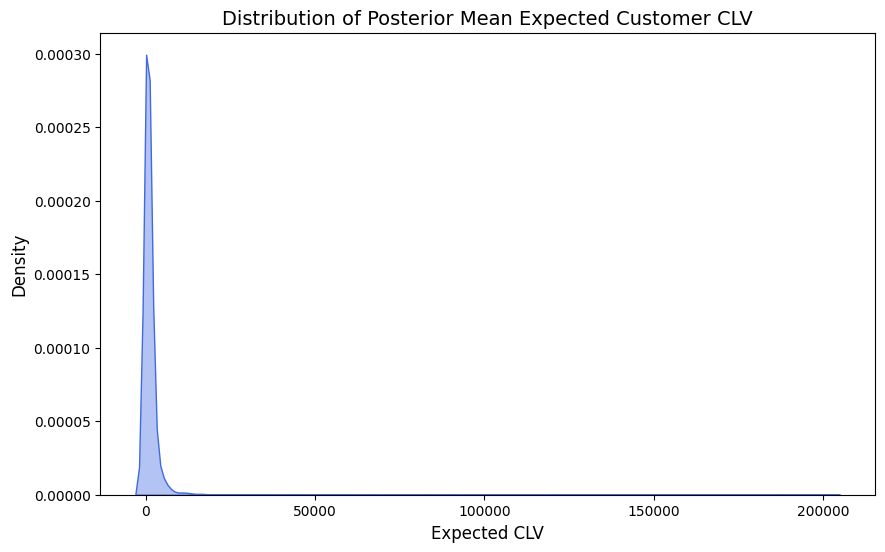

In [23]:

# 2. seaborn 绘制核密度估计图
plt.figure(figsize=(10, 6))
sns.kdeplot(mean_clv_per_customer.values, fill=True, color="royalblue", alpha=0.4)
plt.title("Distribution of Posterior Mean Expected Customer CLV", fontsize=14)
plt.xlabel("Expected CLV", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.show()

偏态很大，用户分层非常有必要

Text(0.5, 1.0, 'Expected mean spend of a new customer')

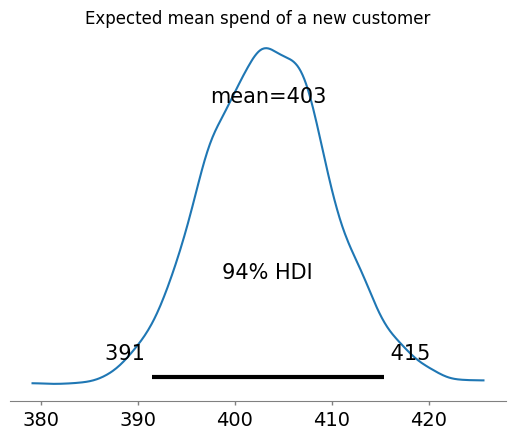

In [24]:
# 新客户的每单平均消费
az.plot_posterior(gg.expected_new_customer_spend())
plt.title("Expected mean spend of a new customer")

## end

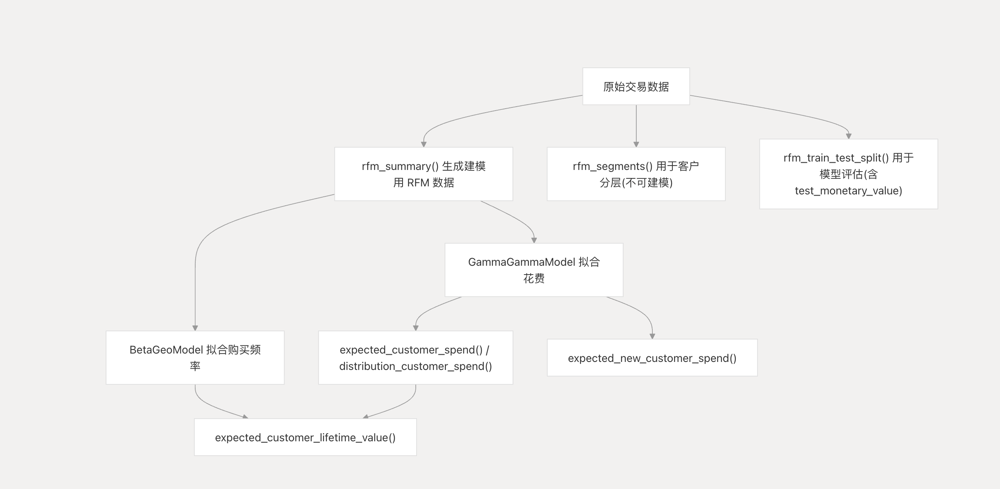

（计算师需要注意以下变量）

这些数值 和RFM 分析中是有区别的：


frequency - 表示客户进行的重复购买次数，这个数字比总购买次数少一次。

recency - 表示客户最近一次购买的时间段。这相当于从客户第一次购买到最后一次购买之间的时间长度。如果客户只进行了一次购买，那么他们的近期性值为 0。

monetary_value - 表示某个客户重复购买行为的平均价值。那些只进行过一次购买的客户的数值为零。


我试一下用这个数据去做 分层。

一种是 rfm_segments 提供了自带的分层。按照【四分位】切分rfm, 切分为5类。

另一种是结合bgm+gg 计算之后的 【kmeans聚类】，同样地我们把k设为5。

两种方法没有优劣之后，但是在看完结果之后，你可以选择合适的。

# rfm_segments 

使用pymc开箱即用函数rfm_segments() 进行的分位切分，并分类、绘制分布图表

In [6]:
# # 1. RFM 分层（独立计算，不用于建模）  
segments = clv.rfm_segments(  
    df,  
    customer_id_col="Customer ID",  
    datetime_col="InvoiceDate",  
    monetary_value_col="TotalPrice",  
)  # -> customer_id, frequency, recency, monetary_value, rfm_score, segment  
  

segments共五类：Premium / Repeat / Top Spender / At Risk / Inactive，未匹配的落入 "Other

In [16]:
segments

,customer_id,frequency,recency,monetary_value,rfm_score,segment
0,12346,8.0,325.0,9694.557500,234,Repeat Customer
1,12347,8.0,2.0,615.191250,434,Premium Customer
2,12348,5.0,75.0,331.680000,323,Top Spender
3,12349,3.0,18.0,1226.230000,414,Top Spender
4,12350,1.0,310.0,294.400000,213,Other
...,...,...,...,...,...,...
5856,18283,19.0,3.0,139.944737,431,Other
5857,18284,1.0,431.0,411.680000,113,Inactive Customer
5858,18285,1.0,660.0,377.000000,113,Inactive Customer
5859,18286,2.0,476.0,623.215000,114,Inactive Customer


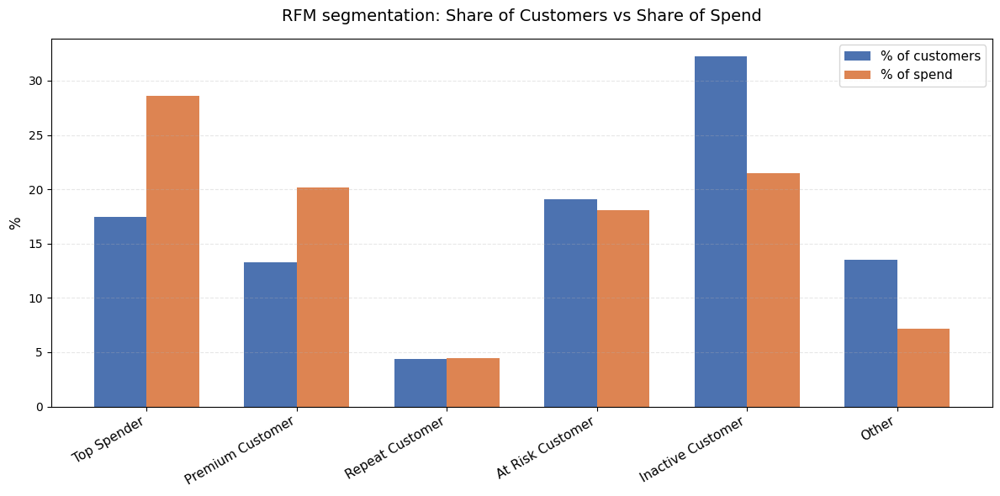

In [17]:
summary_df = (
    segments.groupby('segment')
    .agg(
        customer_count=('customer_id', 'count'),
        total_spend=('monetary_value', 'sum'),
    )
    .reset_index()
)
desired_order = [
    'Top Spender',
    'Premium Customer',
    'Repeat Customer',
    'At Risk Customer',
    'Inactive Customer',
    'Other',
]  # 逻辑顺序调整

summary_df['segment'] = pd.Categorical(
    summary_df['segment'], categories=desired_order, ordered=True
)
summary_df = summary_df.sort_values('segment').reset_index(drop=True)
# 2. 计算百分比 (%)
total_customers = summary_df['customer_count'].sum()
total_spend = summary_df['total_spend'].sum()

summary_df['% of customers'] = (
    summary_df['customer_count'] / total_customers
) * 100
summary_df['% of spend'] = (summary_df['total_spend'] / total_spend) * 100
# 3. 设置绘图样式
plt.figure(figsize=(12, 6))

x = range(len(summary_df))
width = 0.35  # 柱子宽度

# 绘制柱状图
plt.bar(
    [i - width / 2 for i in x],
    summary_df['% of customers'],
    width=width,
    label='% of customers',
    color='#4c72b0',
)
plt.bar(
    [i + width / 2 for i in x],
    summary_df['% of spend'],
    width=width,
    label='% of spend',
    color='#dd8452',
)

# 4. 图表细节美化
plt.title(
    'RFM segmentation: Share of Customers vs Share of Spend',
    fontsize=14,
    pad=15,
)
plt.ylabel('%', fontsize=12)
plt.xticks(
    ticks=x, labels=summary_df['segment'], rotation=30, ha='right', fontsize=11
)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
import plotly.offline as pyo
pyo.init_notebook_mode(connected=True)

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

desired_order = [ 
    'Top Spender',
    'Premium Customer',
    'Repeat Customer',
    'At Risk Customer',
    'Inactive Customer',
    'Other',]
PALETTE = ["#C0392B", "#E67E22", "#27AE60", "#5AC3AE", "#69A3C9",
           "#B56AD5"]


color_map = dict(zip(desired_order, PALETTE))
present = [s for s in desired_order if s in set(segments["segment"])]

def ticks(vals, step_list):
    return [np.log1p(v) for v in step_list], [f"{v:,.0f}" for v in step_list]

F_TICKS = [10, 50, 100, 500, 1_000, 5_000, 10_000, 50_000, 500_000]
M_TICKS = [10, 50, 100,200,300, 400,500, 700,1000,1500, 2000, 5_000, 10_000,50_000, 100_000]
R_TICKS = [1, 7, 30, 90, 180, 365, 740]

def axis_cfg(title, tickvals, ticktext, neg=False):
    tv = [-v for v in tickvals] if neg else tickvals
    return dict(title=title, tickvals=tv, ticktext=ticktext,
                gridcolor="#E5E7EB", showbackground=True,
                backgroundcolor="rgba(247,248,250,0.9)")

f_tv, f_tt = ticks(segments["frequency"], F_TICKS)
m_tv, m_tt = ticks(segments["monetary_value"], M_TICKS)
r_tv, r_tt = ticks(segments["recency"], R_TICKS)

def hover(r):
    return (f"客户 {r['customer_id']}<br>"
            f"分层: {r['segment']}<br>"
            f"Frequency: {r['frequency']:,.0f} 单<br>"
            f"Monetary: {r['monetary_value']:,.0f}<br>"
            f"Recency: {r['recency']:,.0f} 天<br>"
            # f"RFM得分: {r['R']}{r['F']}{r['M']}"
            )

# ---------------- log1p 3D 散点图 ----------------
fig_plotly = go.Figure()

for seg in present:
    g = segments[segments["segment"] == seg]
    fig_plotly.add_trace(go.Scatter3d(
        x=np.log1p(g["frequency"]), 
        y=np.log1p(g["monetary_value"]), 
        z=-np.log1p(g["recency"]),
        mode="markers", 
        name=seg, 
        marker=dict(size=2.8, color=color_map.get(seg, "#BDC3C7"), opacity=0.65),
        text=g.apply(hover, axis=1), 
        hovertemplate="%{text}<extra></extra>",
        showlegend=True,
    ))

fig_plotly.update_layout(
    scene=dict(
        xaxis=axis_cfg("Freq", f_tv, f_tt), 
        yaxis=axis_cfg("Monetary", m_tv, m_tt), 
        zaxis=axis_cfg("Recency（越大越近）", r_tv, r_tt, neg=True), 
        aspectmode="cube"
    ),
    title=dict(
        text="Online Retail II · RFM 分层", 
        x=0.5, font=dict(size=15)
    ),
    width=900, 
    height=650, 
    margin=dict(l=0, r=0, t=60, b=0),
    legend=dict(itemsizing="constant", font=dict(size=11)),
    paper_bgcolor="white",
)

# 聚类

In [47]:
rfm_include_first = clv.rfm_train_test_split(df,
                    train_period_end=train_end,
                    test_period_end=data_end,
                    customer_id_col="Customer ID",  
                    datetime_col="InvoiceDate",  
                    monetary_value_col="TotalPrice", 
                    datetime_format="%Y-%m-%d %H:%M:%S",  
                    time_unit="D",  
                    include_first_transaction=True
                          )

In [48]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
# from sklearn.metrics import silhouette_score

SEED = 42
features = rfm[["customer_id"]].copy()  
features["expected_purchases"] = bgm.expected_purchases(  
    data=rfm, future_t=6  
).mean(("chain", "draw"))  
features["prob_alive"] = bgm.expected_probability_alive(data=rfm).mean(("chain", "draw"))  
features["expected_spend"] = gg.expected_customer_spend(data=rfm).mean(("chain", "draw"))  
features["clv"] = clv_estimate.mean(("chain", "draw"))  

# 
df_merge = features.merge(rfm_include_first, on="customer_id", how="left")

X_log = np.column_stack([np.log1p(df_merge["frequency"]),
                         np.log1p(df_merge["monetary_value"]),
                         -np.log1p(df_merge["recency"])])
X_raw3 = np.column_stack([df_merge["frequency"], df_merge["monetary_value"], -df_merge["recency"]])

scalers = {
    "log1p + MinMaxScaler": MinMaxScaler().fit_transform(X_log),
}
X = MinMaxScaler().fit_transform(X_log)

# k=5  KMeans
SEED = 42
km = KMeans(n_clusters=5, random_state=SEED, n_init=10).fit(X)

# 3. 把聚类标签写回数据表
df_merge["Cluster"] = km.labels_

print('聚类完成！每个簇的样本分布：')
print(pd.Series(km.labels_).value_counts().sort_index())

聚类完成！每个簇的样本分布：
0     514
1    2125
2     698
3    1011
4     570
Name: count, dtype: int64


In [50]:
# cluster profile
prof = df_merge.groupby("Cluster").agg(
    customer_count=("customer_id", "count"),
    R=("recency", "median"),
    F=("frequency", "median"),
    M=("monetary_value", "median")
).round(2)

display(prof)

,customer_count,R,F,M
Cluster,,,,
0,514,14.0,14.0,386.29
1,2125,258.0,1.0,252.07
2,698,70.0,2.0,243.39
3,1011,117.0,5.0,329.85
4,570,16.0,4.0,306.63


In [65]:
# 倾向命名的标签：
label_map = {
    0: "Top Spender",
    1: "Hibernating",
    2: "At Risk",
    3: "Premium Customer",
    4: "New",
   
}



prof["ClusterLabel"] = prof.index.map(label_map)
order = prof.sort_values("M", ascending=False).index.tolist()
prof


,customer_count,R,F,M,ClusterLabel
Cluster,,,,,
0,514,14.0,14.0,386.29,Top Spender
1,2125,258.0,1.0,252.07,Hibernating
2,698,70.0,2.0,243.39,At Risk
3,1011,117.0,5.0,329.85,Premium Customer
4,570,16.0,4.0,306.63,New


# 聚类3D可视化

In [ ]:
import numpy as np
import plotly.graph_objects as go

PAL = ["#C0392B", "#E67E22", "#F1C40F", "#27AE60", "#2980B9"]
color = {c: PAL[i % len(PAL)] for i, c in enumerate(order)}
def hover(r):
    return (f"客户 {r['customer_id']}<br>"
            f"Frequency: {r['frequency']:,.0f} 单<br>"
            f"Monetary: {r['monetary_value']:,.0f}<br>"
            f"Recency: {r['recency']:,.0f} 天<br>"
            )

fig = go.Figure()
for c in order:
    g = df_merge[df_merge["Cluster"] == c]
    fig.add_trace(go.Scatter3d(
        x=np.log1p(g["frequency"]),
        y=np.log1p(g["monetary_value"]),
        z=-np.log1p(g["recency"]),          # recency = 距今天数，取负号后越大越近
        mode="markers",
        name=f"{c} · {label_map[c]}（n={len(g):,}）",
        marker=dict(size=2.5, color=color[c], opacity=0.35),
        customdata=np.stack([g["frequency"], g["monetary_value"],
                             g["recency"], g["clv"]], -1),
        hovertemplate=g.apply(hover, axis=1), 
    ))

fig.update_layout(
    height=760, margin=dict(l=0, r=0, t=30, b=0),
    legend=dict(itemsizing="constant"),
    scene=dict(xaxis_title="frequency",
               yaxis_title="monetary_value",
               zaxis_title="−recency",
               aspectmode="cube"),
)
fig.show()


In [78]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

PAL = ["#C0392B", "#E67E22", "#F1C40F", "#27AE60", "#2980B9"]
color = {c: PAL[i % len(PAL)] for i, c in enumerate(order)}

# recency = 距今天数，取负号后越大越近
AX = {"recency": lambda s: -np.log1p(s),
      "frequency": np.log1p,
      "monetary_value": np.log1p}
name = {"recency": "−recency", "frequency": "frequency", "monetary_value": "monetary_value"}
pairs = [("recency", "frequency"),
         ("recency", "monetary_value"),
         ("frequency", "monetary_value")]

fig = make_subplots(rows=1, cols=3,
                    subplot_titles=[f"{name[a]} × {name[b]}" for a, b in pairs])
for j, (a, b) in enumerate(pairs, start=1):
    for c in order:
        g = df_merge[df_merge["Cluster"] == c]
        fig.add_trace(go.Scattergl(
            x=AX[a](g[a]),
            y=AX[b](g[b]),
            mode="markers",
            name=f"{c} · {label_map[c]}",
            legendgroup=str(c),
            showlegend=(j == 1),
            marker=dict(size=3.5, color=color[c], opacity=0.35),
            customdata=np.stack([g["frequency"], g["monetary_value"],
                                 g["recency"], g["clv"]], -1),
            hovertemplate=g.apply(hover, axis=1),
        ), row=1, col=j)
    fig.update_xaxes(title_text=f"{name[a]}（log1p）", row=1, col=j)
    fig.update_yaxes(title_text=f"{name[b]}（log1p）", row=1, col=j)

fig.update_layout(height=460, margin=dict(l=0, r=0, t=40, b=0),
                  legend=dict(itemsizing="constant"))
fig.show()
